In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
from google.colab import files

uploaded = files.upload()

Saving 2017_jun_final - 2017_jun_final.csv to 2017_jun_final - 2017_jun_final.csv


In [3]:
df = pd.read_csv("2017_jun_final - 2017_jun_final.csv")

In [4]:
df.head()

,N,Посада,Мова програмування,Спеціалізація,Загальний досвід роботи,Досвід роботи на поточному місці,Зарплата на місяць,Зміна зарплати за 12 місяців,Місто,Розмір компанії,...,Ще студент,Рівень англійської,Предметна область,Дата заповнення,User.Agent,exp,current_job_exp,salary,Валюта,cls
0,1,Junior QA engineer,NaN,Manual QA,0.5,0.5,400,0,Харків,до 10 осіб,...,True,Pre-intermediate (нище середнього),"iOS,eCommerce",12/06/2017 12:38:08,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,0.5,0.5,400,NaN,QA
1,2,Junior QA engineer,NaN,Manual QA,менше 3 місяців,менше 3 місяців,430,130,Харків,більше 1000 осіб,...,True,Upper-Intermediate (вище середнього),Веб-розробка,12/06/2017 12:42:51,Mozilla/5.0 (iPad; CPU OS 10_2_1 like Mac OS X...,0.0,0.0,430,NaN,QA
2,3,Software Engineer,C#/.NET,NaN,4,1,2500,800,Київ,до 1000 осіб,...,False,Intermediate (середній),"Веб-розробка,Корпоративні системи",12/06/2017 13:02:47,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,4.0,1.0,2500,NaN,DEV
3,4,Software Engineer,JavaScript,NaN,5,4,2000,400,Одеса,до 200 осіб,...,False,Pre-intermediate (нище середнього),"Desktop Applications,Веб-розробка",12/06/2017 13:03:01,Mozilla/5.0 (Windows NT 6.1; Win64; x64) Apple...,5.0,4.0,2000,NaN,DEV
4,5,Senior Software Engineer,JavaScript,NaN,10 і більше років,0.5,4500,500,Інше,до 10 осіб,...,False,Intermediate (середній),"Desktop Applications,Веб-розробка",12/06/2017 13:03:47,Mozilla/5.0 (iPhone; CPU iPhone OS 10_3_2 like...,10.0,0.5,4500,NaN,DEV


In [5]:
df.shape

(8704, 25)

In [6]:
df.dtypes

,0
N,int64
Посада,object
Мова програмування,object
Спеціалізація,object
Загальний досвід роботи,object
Досвід роботи на поточному місці,object
Зарплата на місяць,int64
Зміна зарплати за 12 місяців,int64
Місто,object
Розмір компанії,object


In [7]:
df.isnull().sum() / len(df)

,0
N,0.000000
Посада,0.000000
Мова програмування,0.442325
Спеціалізація,0.829389
Загальний досвід роботи,0.000000
Досвід роботи на поточному місці,0.000000
Зарплата на місяць,0.000000
Зміна зарплати за 12 місяців,0.000000
Місто,0.000000
Розмір компанії,0.000000


In [8]:
df = df.drop(columns=[
    col for col in df.columns
    if df[col].isnull().any() and col != "Мова програмування"
])

In [9]:
df.isnull().sum() / len(df)

,0
N,0.000000
Посада,0.000000
Мова програмування,0.442325
Загальний досвід роботи,0.000000
Досвід роботи на поточному місці,0.000000
Зарплата на місяць,0.000000
Зміна зарплати за 12 місяців,0.000000
Місто,0.000000
Розмір компанії,0.000000
Тип компанії,0.000000


In [10]:
df = df.dropna()

In [11]:
df.shape

(4854, 20)

In [12]:
python_data = df[df["Мова програмування"] == "Python"]
python_data.head()

,N,Посада,Мова програмування,Загальний досвід роботи,Досвід роботи на поточному місці,Зарплата на місяць,Зміна зарплати за 12 місяців,Місто,Розмір компанії,Тип компанії,Стать,Вік,Освіта,Ще студент,Рівень англійської,Дата заповнення,User.Agent,exp,current_job_exp,salary
12,13,Software Engineer,Python,1,менше 3 місяців,800,200,Київ,до 50 осіб,Аутсорсингова,чоловіча,26,Вища,False,Pre-intermediate (нище середнього),12/06/2017 13:05:54,Mozilla/5.0 (Windows NT 6.1; Win64; x64) Apple...,1.0,0.0,800
68,69,Software Engineer,Python,1.5,0.5,900,900,Київ,до 10 осіб,Стартап,чоловіча,21,Неповна Вища,True,Upper-Intermediate (вище середнього),12/06/2017 13:11:17,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1.5,0.5,900
87,88,Junior Software Engineer,Python,0.5,0.5,600,0,Київ,до 10 осіб,Аутсорсингова,чоловіча,19,Неповна Вища,True,Upper-Intermediate (вище середнього),12/06/2017 13:12:25,Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/53...,0.5,0.5,600
114,115,Junior Software Engineer,Python,1.5,0.5,685,250,Київ,до 1000 осіб,Аутсорсингова,чоловіча,21,Неповна Вища,False,Intermediate (середній),12/06/2017 13:14:52,Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/53...,1.5,0.5,685
143,144,Junior Software Engineer,Python,1,1,750,250,Київ,до 10 осіб,Аутсорсингова,чоловіча,21,Неповна Вища,True,Upper-Intermediate (вище середнього),12/06/2017 13:19:10,Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/53...,1.0,1.0,750


In [13]:
python_data.shape

(207, 20)

In [14]:
grouped = python_data.groupby("Посада")

In [15]:
salary_stats = grouped["Зарплата на місяць"].agg(["min", "max"])

salary_stats

,min,max
Посада,,
Junior Software Engineer,100,1250
Senior Software Engineer,1300,9200
Software Engineer,500,5400
System Architect,3000,5000
Technical Lead,1425,6200


In [16]:
def fill_avg_salary(row):
    return (row["min"] + row["max"]) / 2

salary_stats["avg"] = salary_stats.apply(fill_avg_salary, axis=1)

salary_stats

,min,max,avg
Посада,,,
Junior Software Engineer,100,1250,675.0
Senior Software Engineer,1300,9200,5250.0
Software Engineer,500,5400,2950.0
System Architect,3000,5000,4000.0
Technical Lead,1425,6200,3812.5


In [17]:
salary_stats["avg"].describe()

,avg
count,5.000000
mean,3337.500000
std,1700.091909
min,675.000000
25%,2950.000000
50%,3812.500000
75%,4000.000000
max,5250.000000


In [18]:
salary_stats.to_csv("python_salary_stats.csv", encoding="utf-8-sig")

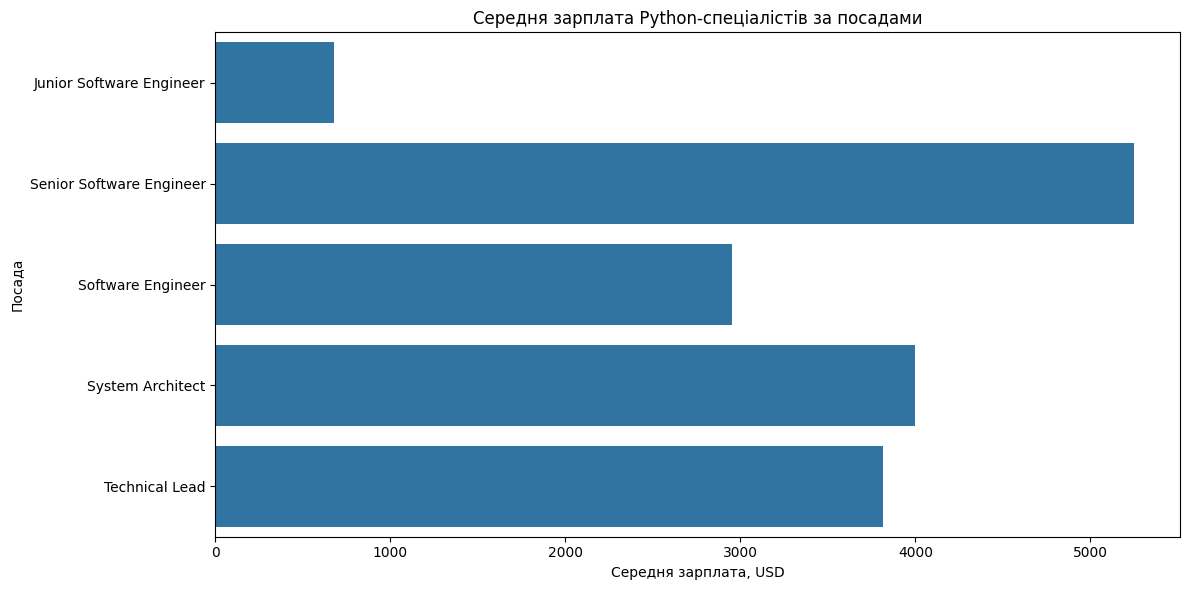

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    x=salary_stats["avg"].values,
    y=salary_stats.index
)

plt.title("Середня зарплата Python-спеціалістів за посадами")
plt.xlabel("Середня зарплата, USD")
plt.ylabel("Посада")
plt.tight_layout()
plt.show()

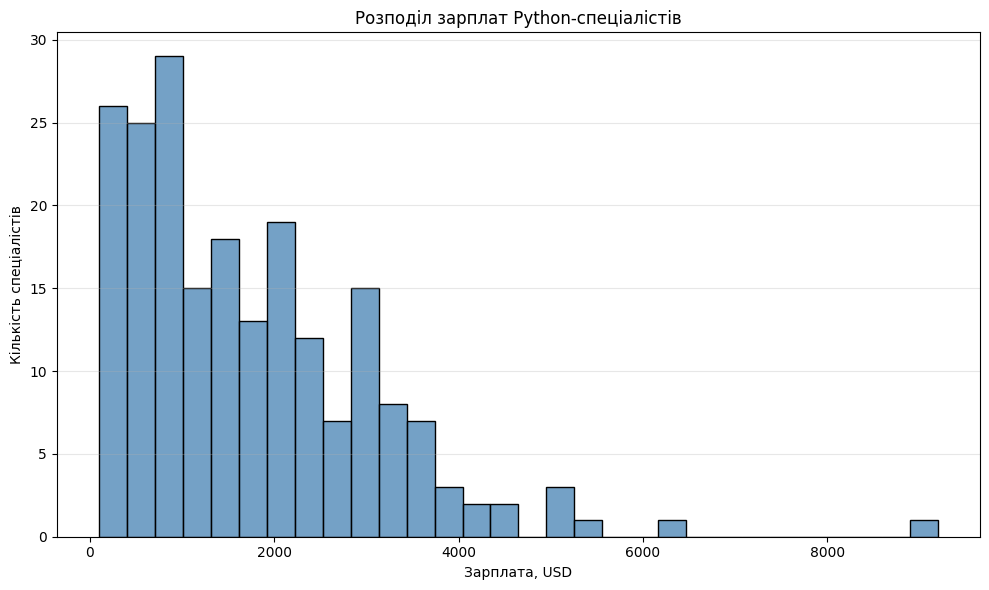

In [20]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=python_data,
    x="Зарплата на місяць",
    bins=30,
    color="steelblue"
)

plt.title("Розподіл зарплат Python-спеціалістів")
plt.xlabel("Зарплата, USD")
plt.ylabel("Кількість спеціалістів")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

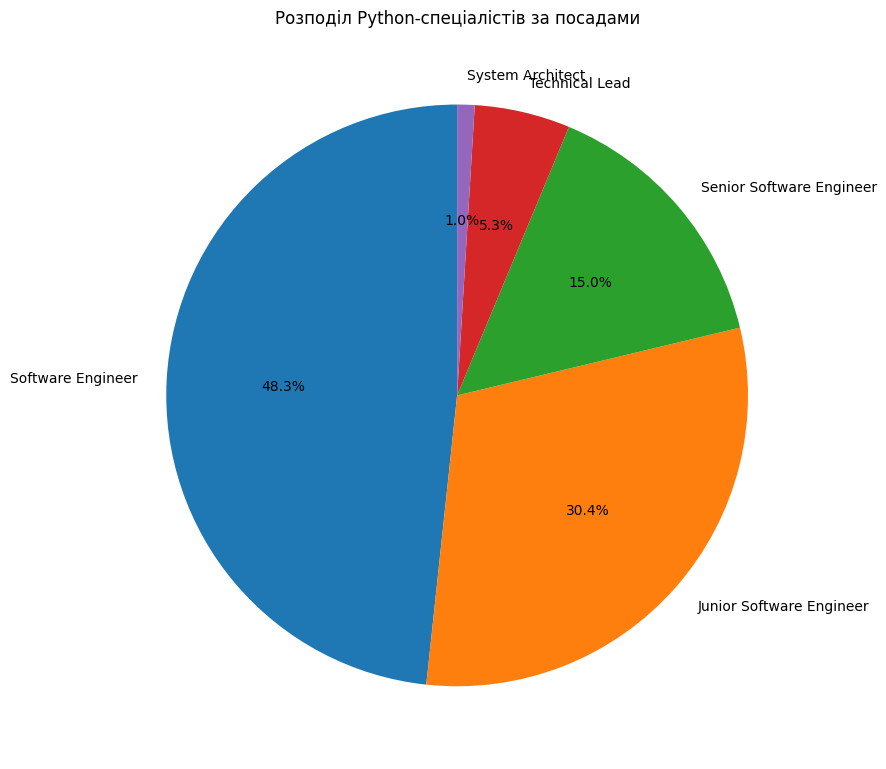

In [21]:
positions = python_data["Посада"].value_counts()

plt.figure(figsize=(9, 9))

plt.pie(
    positions.values,
    labels=positions.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Розподіл Python-спеціалістів за посадами")
plt.tight_layout()
plt.show()